# Exploratory data analysis
Artifical data will be analyzed to gain a better understanding.

In [1]:
#import
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme()

In [3]:
# dataset folder
DATASET_NOISE = "../../datasets/pk_128_train_250325_noise/"
DATASET_CLEAN = "../../datasets/pk_128_train_250325/"

# Redshift frequencies

In [10]:
z_freq = pl.read_csv(DATASET_NOISE + "redshifts_freqs.txt", separator="\t")

In [5]:
print(f"minimum redshift: {z_freq["# z"].min()}\tmaximum redshift: {z_freq["# z"].max()}")
print(f"minimum frequency: {z_freq["freq [MHz]"].min()}\tmaximum frequency: {z_freq["freq [MHz]"].max()}")

minimum redshift: 5.5	maximum redshift: 19.959
minimum frequency: 67.75	maximum frequency: 218.46


In the data specification, the min-max of redshift and frequencies are:

z = {6.25; 8.41} \
freq = {151; 195.9}

Provided data has a larger redshift and frequency range

(array([152., 116.,  91.,  75.,  63.,  53.,  47.,  40.,  36.,  33.]),
 array([ 5.5   ,  6.9459,  8.3918,  9.8377, 11.2836, 12.7295, 14.1754,
        15.6213, 17.0672, 18.5131, 19.959 ]),
 <BarContainer object of 10 artists>)

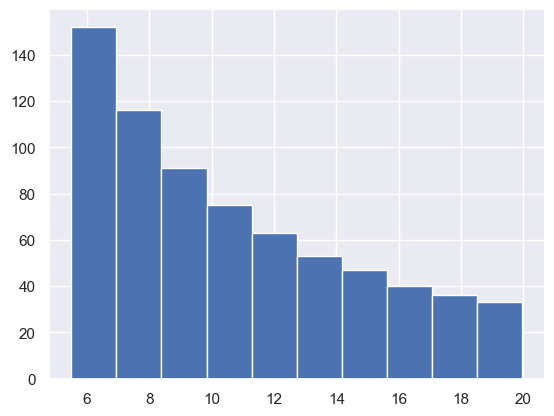

In [6]:
plt.hist(z_freq['# z'])

# Inputs
Power spectrums

In [16]:
ps_files = os.listdir(DATASET_NOISE + "inputs/")

print(f"{len(ps_files)} power spectra files")

478350 power spectra files


In [ ]:
ps_array = np.loadtxt(DATASET_NOISE + "inputs/" + ps_files[0], delimiter=" ")

print(f"{ps_array.shape[0]} x {ps_array.shape[1]} matrix")

10 x 10 matrix


In [ ]:
# checking that all files have a 10 by 10 matrix
shape = (10, 10)
i = 0
for file in ps_files:
    ps_shape = np.loadtxt(DATASET_NOISE + "inputs/" + ps_files[0], delimiter=" ").shape
    if (ps_shape != shape):
        i+=1
        print(i)

print(f"There are {i} spectra that do not match the 10 x 10 matrix shape")

There are 0 spectras that do not match the 10 x 10 matrix shape


All 478350 power spectra possess a 10x10 matrix.

Each index has three power spectra representing their specific frequency range, so in total there are three samples per index, 159'450 indices.

# Targets

In [26]:
target_files = os.listdir(DATASET_NOISE + "/targets")
sample_target = pl.read_csv(DATASET_NOISE + "/targets/" + target_files[0], separator="\t")

sample_target

# z,mean_xHI
f64,f64
7.962,0.72791
7.189,0.57704
6.536,0.41716


For three specific redshifts that are respectively in each of the three ranges, there is a target reionisation fraction.

In [ ]:
# checking the range of redshifts for all target files
z1_min = np.inf
z1_max = 0
z2_min = np.inf
z2_max = 0
z3_min = np.inf
z3_max = 0

# checking and checking
for file in target_filesfiles:
    target = np.loadtxt(DATASET_NOISE + "/targets/" + file, delimiter="\t")

    z1, z2, z3 = target[0][0], target[1][0], target[2][0]

    z1_min = min(z1, z1_min)
    z2_min = min(z2, z2_min)
    z3_min = min(z3, z3_min)
    
    z1_max = max(z1, z1_max)
    z2_max = max(z2, z2_max)
    z3_max = max(z3, z3_max)

print("redshift ranges...")
print(f"z1:\tmin: {z1_min}\tmax: {z1_max}")
print(f"z2:\tmin: {z2_min}\tmax: {z2_max}")
print(f"z3:\tmin: {z3_min}\tmax: {z3_max}")

redshift ranges...
z1:	min: 7.962	max: 7.962
z2:	min: 7.189	max: 7.189
z3:	min: 7.189	max: 7.189


redshift values are constant for each of the ~160'000 targets:

$z_{1} = 7.962$, this is in the range 151-165.9 MHz

$z_{2} = 7.189$, this is in the range 166-180.9 MHz

$z_{3} = 6.536$, this is in the range 181-195.9 MHz

They are each slightly under the average redshift of their range.